In [1]:
import pandas as pd

labels = pd.read_csv("../data/labels/labeled.csv", encoding="utf-8-sig")
key = pd.read_csv("../data/labels/sample_key.csv", dtype={"CAMPNO": str})
ev = labels.merge(key, on="sample_id", validate="one_to_one")

X = ev["DESC_DEFECT"] + " " + ev["CONEQUENCE_DEFECT"]
y = ev["label"]
print(X.shape, y.value_counts().to_dict())

(200,) {0: 118, 1: 82}


In [2]:
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

def report(name, y_true, y_pred):
    print(f"{name}: P={precision_score(y_true, y_pred):.3f} "
          f"R={recall_score(y_true, y_pred):.3f} F1={f1_score(y_true, y_pred):.3f}")
    print(confusion_matrix(y_true, y_pred))

baseline = ev["battery_fire"].astype(int)
report("Regex baseline", y, baseline)

Regex baseline: P=0.810 R=0.988 F1=0.890
[[99 19]
 [ 1 81]]


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "TF-IDF + LogReg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "TF-IDF + RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
}

preds = {}
for name, clf in models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english"), clf)
    preds[name] = cross_val_predict(pipe, X, y, cv=cv)
    report(name, y, preds[name])

TF-IDF + LogReg: P=0.835 R=0.866 F1=0.850
[[104  14]
 [ 11  71]]
TF-IDF + RandomForest: P=0.881 R=0.902 F1=0.892
[[108  10]
 [  8  74]]


In [4]:
rf = preds["TF-IDF + RandomForest"]
two_stage = (baseline == 1) & (rf == 1)
report("Regex -> RF (two-stage)", y, two_stage.astype(int))

Regex -> RF (two-stage): P=0.912 R=0.890 F1=0.901
[[111   7]
 [  9  73]]


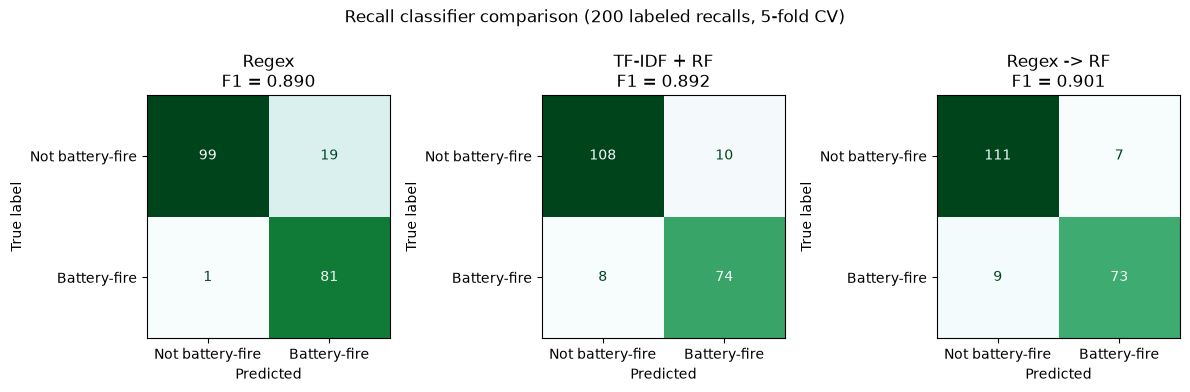

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

results = {
    "Regex": baseline,
    "TF-IDF + RF": rf,
    "Regex -> RF": two_stage.astype(int),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, pred) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y, pred, display_labels=["Not battery-fire", "Battery-fire"],
        cmap="BuGn", colorbar=False, ax=ax)
    ax.set_title(f"{name}\nF1 = {f1_score(y, pred):.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True label")

fig.suptitle("Recall classifier comparison (200 labeled recalls, 5-fold CV)")
fig.tight_layout()
fig.savefig("../figures/04_classifier_confusion.png", dpi=150, bbox_inches="tight")
plt.show()